# Employee Attrition Analytics — Exploratory Data Analysis (EDA)

## 1. Introduction

### Project Overview

This notebook forms the second stage of the Employee Attrition Analytics project, following the Extract, Transform and Load (ETL) process.

The project uses the publicly available **IBM HR Analytics Employee Attrition & Performance** synthetic dataset to examine key trends related to organisational turnover.

The cleaned dataset cosists of **1,470 employee records and 35 columns**, including three custom features generated during preprocessing.

The main objective of this analysis is to uncover significant patterns in employee attrition and deliver actionable insights that drive data-informed workforce planning and targeted retention strategies.

### Business Problem

Staff turnover introduces replacement costs, operational disruption, and reduced organizational effectiveness. While analyzing attrition variances across employee demographics helps HR teams identify priority areas for deeper study, observed associations must not be interpreted as causal drivers of turnover.

### EDA Objectives

To guide strategy, this analysis will evaluate five key business questions:

1. **Overall Attrition:** What proportion of total staff have left the company?
2. **Department and Job Role:** How do attrition rates vary across departments and job roles?
3. **Overtime:** Does working extra hours correlate with higher employee attrition?
4. **Job Satisfaction:** How does attrition vary across job satisfaction levels?
5. **Employee Tenure:** Are newer hires departing at higher rates than long-tenured employees?

### Analytical Approach

The notebook will utilise:

- Descriptive statistics to summarise the workforce.
- Segmented attrition rates to compare employee categories.
- Python visualisations to highlight key distributions and correlations.
- Chi-square tests of independence to investigate realationships across categorical variables.
- Business interpretations to detail the relevance and constraints of findings.

Outputs from this notebook will directly feed into two Tableau dashboards: **Workforce Overview** and **Attrition Drivers**.

### Ethical Considerations

**Privacy & Protection:** The dataset is purely synthetic and free of real employee identities, though sensitive workforce traits are analyzed responsibly.

**Aggregated Reporting:** Insights are reported at a group level, and demographic data will not be applied toward biased employment actions.

**Analytical Integrity:** Correlation will not be presented as causation, and the inherent limits of synthetic data will be clearly acknowledged.


In [1]:
# Import the required Python libraries

# Data manipulation
import pandas as pd

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical testing
from scipy.stats import chi2_contingency

# File paths
from pathlib import Path

# Set a consistent visualisation style
sns.set_theme(style="whitegrid")

print("EDA libraries imported successfully.")


EDA libraries imported successfully.


## 2. Loading the Cleaned Dataset

The exploratory analysis uses the processed dataset created in the ETL stage, rather than the original raw CSV.

Using the validated dataset ensures that all visualisations and statistical calculations are based on consistent data, including the engineered `Attrition_Flag`, `Age_Group` and `Tenure_Group` features.

The dataset is loaded from the versioned `data/cleaned/v1/` directory to support reproducibility.

In [6]:
print(Path.cwd())

c:\Users\munta\OneDrive\employee-attrition-analytics\Employee-Attrition-Analytics\jupyter_notebooks\jupyter_notebooks


In [7]:
# Define the path to the cleaned dataset
file_path = Path("../../data/cleaned/v1/employee_attrition_cleaned.csv")

# Load the cleaned dataset
df = pd.read_csv(file_path)

# Verify that the dataset loaded correctly
print("Dataset shape:", df.shape)
print("Total employees:", len(df))
print("Total employees who left:", df["Attrition_Flag"].sum())

# Show the first five rows
display(df.head())


Dataset shape: (1470, 35)
Total employees: 1470
Total employees who left: 237


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition_Flag,Age_Group,Tenure_Group
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,8,0,1,6,4,0,5,1,36-45,6-10 years
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,10,3,3,10,7,1,7,0,46-55,6-10 years
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,7,3,3,0,0,0,0,1,36-45,0-2 years
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,8,3,3,8,7,3,0,0,26-35,6-10 years
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,6,3,3,2,2,2,2,0,26-35,0-2 years


## 3. Overall Employee Attrition Analysis

### Business Question 1: What proportion of employees have left the organisation?

The overall employee attrition rate provides a baseline for understanding how well the organisation retains its employees.

In this dataset, attrition refers to employees leaving an organisation. The `Attrition` column marks employees who have left as (`Yes`) and those who stayed as (`No`).

The attrition rate is calculated as:

**Attrition Rate (%) = (Number of Employees Who Left / Total Employees) × 100**

This analysis will count the number of employees in each attrition category and their pencentages then visualise the distribution using a bar chart.

The findings will serve as a starting point for comparing attrition patterns across departments, job roles and other employee characteristics.

In [8]:
# Calculate employees in each attrition category
attrition_counts = df["Attrition"].value_counts()

# Count the percentage of employees in each category
attrition_percentages = (
    df["Attrition"].value_counts(normalize=True) * 100
)

# Display the results
print("Employee Attrition Counts:")
print(attrition_counts)

print("\nEmployee Attrition Percentages:")
print(attrition_percentages.round(2))

# Calculate the overall attrition rate
overall_attrition_rate = df["Attrition_Flag"].mean() * 100

print(f"\nOverall Attrition Rate: {overall_attrition_rate:.2f}%")


Employee Attrition Counts:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Employee Attrition Percentages:
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64

Overall Attrition Rate: 16.12%


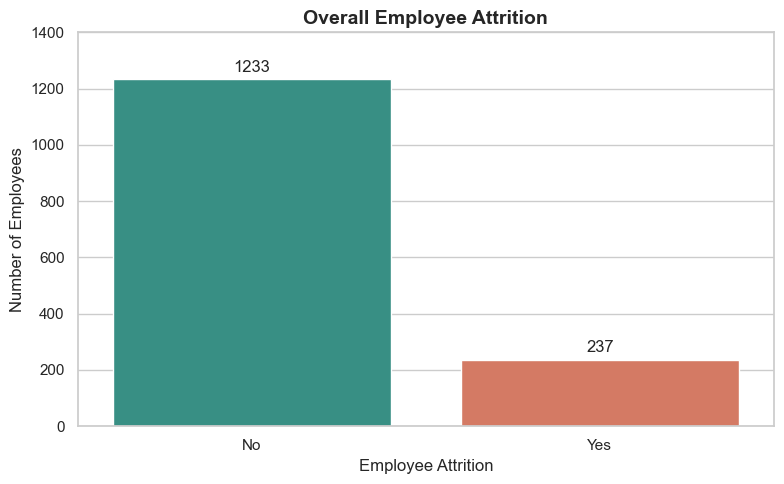

In [10]:
# Create a bar chart to visualize 
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Attrition",
    order=["No", "Yes"],
    hue="Attrition",
    hue_order=["No", "Yes"],
    palette={"No": "#2A9D8F", "Yes": "#E76F51"},
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Overall Employee Attrition", fontsize=14, fontweight="bold")
plt.xlabel("Employee Attrition")
plt.ylabel("Number of Employees")
plt.ylim(0, 1400)

plt.tight_layout()
plt.show()


### Findings and Business Interpretation

The analysis identified **237 employees (16.12%)** who left the organisation, compared with **1,233 employees (83.88%)** who stayed.

The bar chart confirms that retained personnel (the non-attrition group) make up the vast majority of the dataset. Approximately one in six employee records is classified as having experienced attrition.

**Business Implications**

The overall attrition rate of 16.12% provides a reference point for comparing employee teams, departments, job roles and working conditions. Identifying groups above this baseline helps pinpoint operational areas may warrant closer HR review.

However, the findings do not explain why employees left, and because the dataset does not specify an observation period, this figure should not be interpreted as an annual turnover rate.

**Limitations**

The dataset contains synthetic employee records, so findings should not be applied to real organisations without further supporting evidence.

**Key Finding:** The overall employee attrition rate is 16.12%, providing a reference point for subsequent analysis.

## 4. Department and Job Role Attrition Analysis

### Business Question 2: Which departments and job roles have the highest employee attrition rates?

Employee attrition may differ by departments and job role, as employees in different groups can have varying work environments, responsibilities and employment conditions.

This analysis aims to compare attrition rates across departments and job roles with the organisation-wide benchmark of 16.12%.

Instead of only looking at how many employees left the company, this analysis will calculate the **attrition rate for each group**. This makes it easier to compare departments and job roles of different sizes, in a more meaningful way.

The results may help HR teams spot areas that may need further review and guide focused employee retention strategies.

However, differences in attrition rates alone do not explain the reasons behind employee departures.

In [11]:
# Group employees by department and calculate attrition statistics
department_attrition = (
    df.groupby("Department")
    .agg(
        Total_Employees=("EmployeeNumber", "count"),
        Employees_Left=("Attrition_Flag", "sum"),
        Attrition_Rate=("Attrition_Flag", "mean")
    )
    .reset_index()
)

# Convert the attrition rate into a percentage
department_attrition["Attrition_Rate"] = (
    department_attrition["Attrition_Rate"] * 100
).round(2)

# Sort departments from highest to lowest attrition rate
department_attrition = department_attrition.sort_values(
    by="Attrition_Rate",
    ascending=False
)

display(department_attrition)


,Department,Total_Employees,Employees_Left,Attrition_Rate
2,Sales,446,92,20.63
0,Human Resources,63,12,19.05
1,Research & Development,961,133,13.84


### Department Attrition Rate Visualisation

A horizontal bar chart is used to compare attrition rates across departments.

Attrition percentages are more useful than raw departure counts for this comparison because departments differ in workforce sizes.

A reference line marking the overall organisational attrition rate of 16.12% provides a benchmark, showing which departments are above or below the baseline.

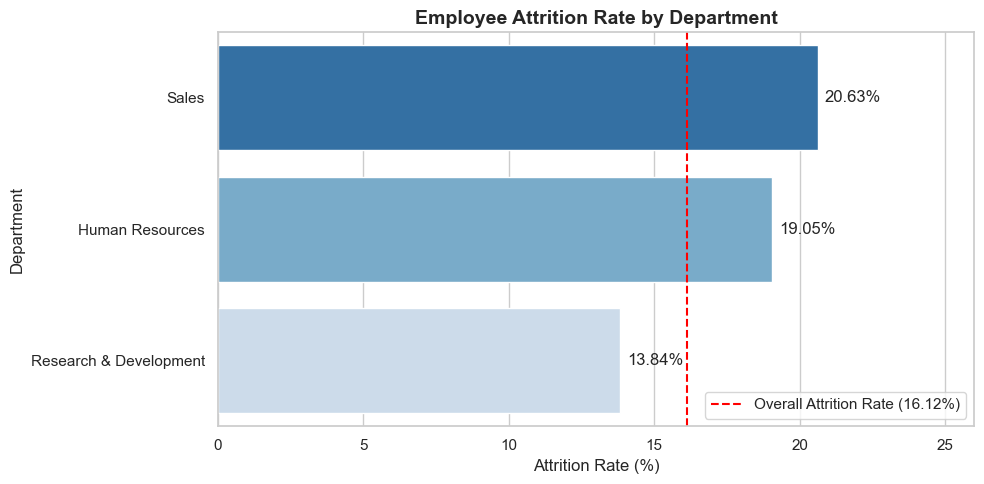

In [12]:
# Make a horizontal bar chart of department attrition rates
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=department_attrition,
    x="Attrition_Rate",
    y="Department",
    hue="Department",
    palette="Blues_r",
    legend=False
)

# Add the overall attrition rate as a reference line
plt.axvline(
    x=overall_attrition_rate,
    color="red",
    linestyle="--",
    label=f"Overall Attrition Rate ({overall_attrition_rate:.2f}%)"
)

# Show percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title("Employee Attrition Rate by Department",
          fontsize=14, fontweight="bold")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Department")
plt.xlim(0, 26)
plt.legend()

plt.tight_layout()
plt.show()


### Department Attrition: Findings and Business Interpretation

The analysis reveals differences in employee attrition rates across the three departments.

**Key Findings**

- **Sales:** Had the highest attrition rate at **20.63%**, with 92 of 446 employees leaving. This is 4.51 percentage points above the organisational wide-rate of 16.12%.
- **Human Resources:** Had an attrition rate of **19.05%**, with 12 of 63 employees leaving the organisation. This is 2.93 percentage points above the overall baseline.
- **Research & Development:** Recorded the lowest attrition rate at **13.84%**, with 133 of 961 employees leaving. Despite it having the largest number of leavers, its attrition rate stayed below the overall organisational rate.

**Business Implications**

The Sales department may be a priority for further investigation as it has the highest proportion of employees recorded as leaving.

Human Resources was also above the overall attrition rate. Although its workforce is smaller, a relatively small number of departures can have a noticeable effect on its percentage.

Research & Development illustrated why comparing attrition rates, rather that departure counts alone, is useful when departments differ in size.

These findings could help HR teams give priority to  further investigation into the experiences of employees, workload practices as well as and retention.

**Analytical Limitations**

These descriptive results do not explain why employees left. More information would be needed to assess whether working conditions, management practices, or other factors are related to employee attrition. 

Moreover, the dataset is artificially generated (synthetic), so the findings should not be generalised to real organisations.

**Key Insight:** Sales has the highest departmental attrition rate at 20.63%, which was 4.51 percentage above the overall organisational baseline.

### Job Role Attrition Analysis

While department-level analysis gives a broad view of employee attrition, looking at individual job roles provides a more detailed picture of workforce retention patterns.

Different job roles may involve different responsibilities, workloads and working conditions, which may have an associated with different employee attrition variations.

This analysis will calculate the total number of employees, the number of departures, as well as the attrition rate for each of the nine job roles.

**Analytical Approach**

Attrition rates will be evaluated using relative turnover percentages per job role, rather than relying solely on raw departure counts.

The findings will be sorted in descending order by turnover rate and benchmarked against the company baseline of 16.12%.

This approach allows roles of different workforce sizes to be compared and helps highlight areas for further investigation.

It should be noted, however, that observed variables will be interpreted solely as associated factors rather than evidence of causation.

In [13]:
# Group employees by job role and calculate attrition statistics
job_role_attrition = (
    df.groupby("JobRole")
    .agg(
        Total_Employees=("EmployeeNumber", "count"),
        Employees_Left=("Attrition_Flag", "sum"),
        Attrition_Rate=("Attrition_Flag", "mean")
    )
    .reset_index()
)

# Convert attrition rates into percentages
job_role_attrition["Attrition_Rate"] = (
    job_role_attrition["Attrition_Rate"] * 100
).round(2)

# Sort job roles from highest to lowest attrition rate
job_role_attrition = job_role_attrition.sort_values(
    by="Attrition_Rate",
    ascending=False
)

# Display the results
display(job_role_attrition)


,JobRole,Total_Employees,Employees_Left,Attrition_Rate
8,Sales Representative,83,33,39.76
2,Laboratory Technician,259,62,23.94
1,Human Resources,52,12,23.08
7,Sales Executive,326,57,17.48
6,Research Scientist,292,47,16.10
4,Manufacturing Director,145,10,6.90
0,Healthcare Representative,131,9,6.87
3,Manager,102,5,4.90
5,Research Director,80,2,2.50


### Job Role Attrition Rate Visualisation

A horizontal bar chart is utilised to compare employee attrition rates across the nine job roles, ranked in a descending order to make differences between groups easier to see. 

A dashed reference line marks the overall organisational attrition rate of **16.12%**.

This visualisation uses relative percentages rather than raw deaprture counts to account for differing staff levels across job roles.

These findings will help highlight job roles with elevated turnover that may require further examination.

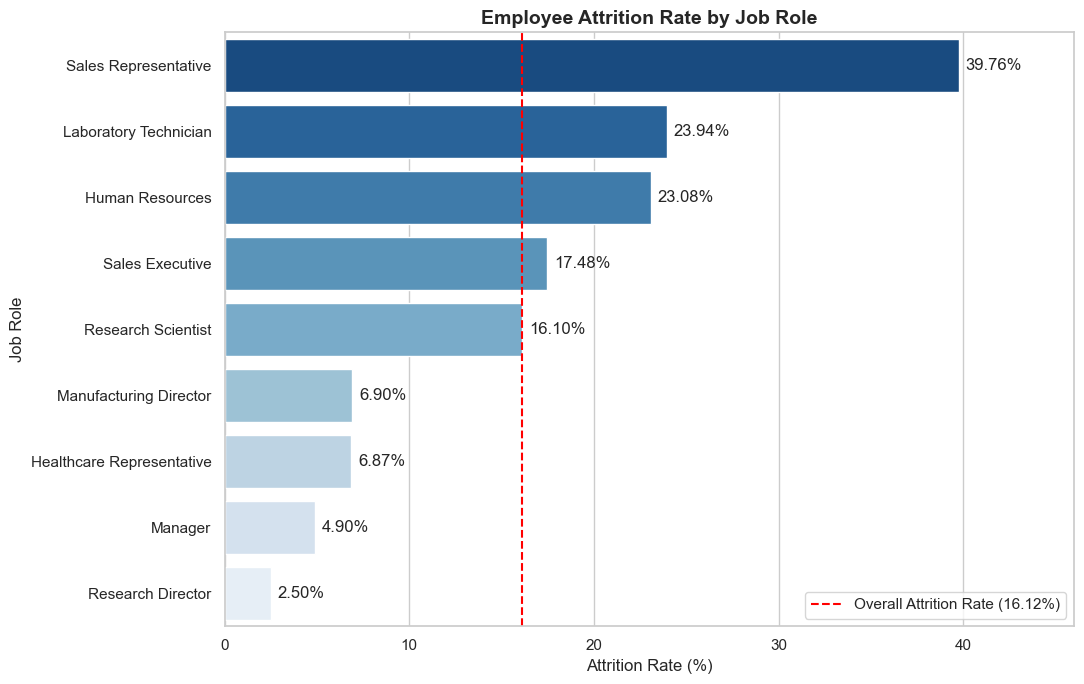

In [14]:
# Make a horizontal bar chart of job role attrition rates
plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=job_role_attrition,
    x="Attrition_Rate",
    y="JobRole",
    hue="JobRole",
    palette="Blues_r",
    legend=False
)

# Include the overall attrition rate reference line
plt.axvline(
    x=overall_attrition_rate,
    color="red",
    linestyle="--",
    label=f"Overall Attrition Rate ({overall_attrition_rate:.2f}%)"
)

# Add percentage labels to the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title(
    "Employee Attrition Rate by Job Role",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")
plt.xlim(0, 46)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()


### Job Role Attrition: Findings and Business Interpretation

The data and the bar chart both show clear differences in employee attrition across the nine job roles.

**Key Findings**

- **Sales Representative:** Recorded the highest attrition rate at **39.76%** (33 departures out of 83 employees). This is 23.64 percentage points above the the company average of 16.12%.
- **Laboratory Technician:** Recorded the second-highest turnover rate at **23.94%** (62 departures out of 250 employees).
- **Human Resources:** Attrition rate of **23.08%**(12 departures out of 52 employees).
- **Sales Executive:** Turover rate of **17.48%**, slightly above the 16.12%.
- **Research Director:** Lowest attrition rate recorded at **2.50%** (only 2 departures out of 80 employees).
- **Research Scientists:** Attrition rate of **16.10%** virtually matching the company baseline.

**Business Implications**

Sales Representatives need the most urgent attention due to their departure rates being significantly higher than any other group within the organisation.

Laboratory Technicians also need a close review because they had the largest total number of departures (62 employees) 

These findings suggest that HR teams should examine job satisfaction, workloads, career growth, opportunities and retention practices in these specific roles.

However, further evidence is required to prove whether these factors are associated with the higher turnover rates.

**Analytical Limitations**

the study points out differences in departure rates, but it does not prove why employees left.

Some job roles are smaller with fewer employees.These roles can see their attrition percentages swing widly from just one or two people leaving. 

Moreover, since this dataset is synthetic, these trends should not be assumed to match real-world companies without supporting evidence.

**Key Insight:** Sales Representatives had the highest attrition rate (39.76%), while Laboratory Technicians had the most departures at (62).

## 5. Overtime and Employee Attrition Analysis

### Business Question 3: Is working overtime associated with higher employee attrition?

Working overtime may be linked to employee retention, as longer working hours can affect workload, the wellbeing of the employee, annd work-life balance.

This analysis aims to compare attrition rates for employees who work overtime and those who do not.

In he `OverTime` column employees who work overtime will be identified as (`Yes`) and those who do not will be marked as (`No`).

**Analytical Approach**

The analysis will:

- Count the total number of employees in each overtime category.
- Calculate the amount of employees that left in each group.
- Calculate and compare each group's attrition rate (those that work overtime and those that do not).
- Display the results in a bar chart.
- Compare both group attrition rates with the overall organisational attrition rate of **16.12%**.

**Business Relevance**

The comparison of the two groups that will take place, could help HR teams identify potential retention concerns and it could help them decide whether working patterns need further investigation.

However, this is an observational analysis and cannot confidentially state whether overtime directly causes employees to depart.

Later on in the notebook, a chi-square test of independence will be conducted later to assess whether the observed association is statistically significant.

In [15]:
# Group employees by overtime status
overtime_attrition = (
    df.groupby("OverTime")
    .agg(
        Total_Employees=("EmployeeNumber", "count"),
        Employees_Left=("Attrition_Flag", "sum"),
        Attrition_Rate=("Attrition_Flag", "mean")
    )
    .reset_index()
)

# Convert attrition rates into percentages
overtime_attrition["Attrition_Rate"] = (
    overtime_attrition["Attrition_Rate"] * 100
).round(2)

# Sort overtime categories for easier comparison
overtime_attrition["OverTime"] = pd.Categorical(
    overtime_attrition["OverTime"],
    categories=["No", "Yes"],
    ordered=True
)

overtime_attrition = overtime_attrition.sort_values("OverTime")

# Display the results
display(overtime_attrition)


,OverTime,Total_Employees,Employees_Left,Attrition_Rate
0,No,1054,110,10.44
1,Yes,416,127,30.53


### Overtime Attrition Rate Visualisation

To compare attrition rates between employees who work overtime and employees who do not, a bar chart is utilized. 

The chart shows attrition percentages rather than departure total, so that the two groups can be compared despite having different numbers of employees.

A dashed reference line represents the organiation-wide attrition rate of **16.12%** as a benchmark for both group to be compared against.

This chart helps show whether attrition rates differ by overtime status. However it alone cannot establish statistical significance or prove causation.

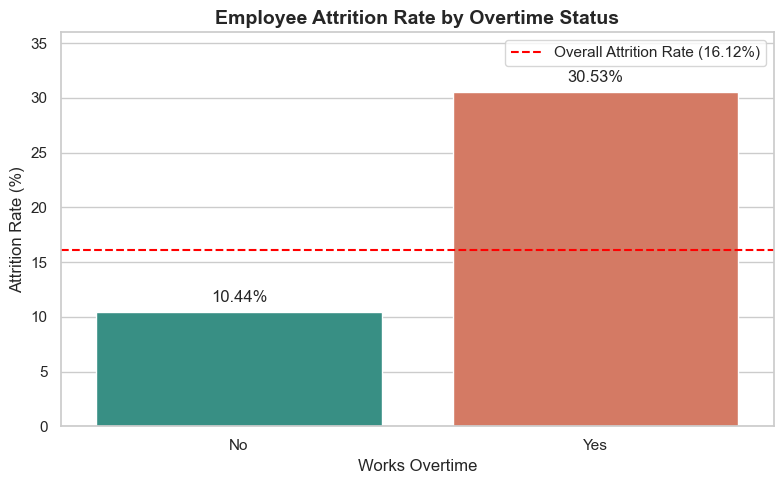

In [16]:
# Create a bar chart comparing overtime attrition rates
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=overtime_attrition,
    x="OverTime",
    y="Attrition_Rate",
    hue="OverTime",
    palette={"No": "#2A9D8F", "Yes": "#E76F51"},
    legend=False
)

# Add the overall attrition rate reference line
plt.axhline(
    y=overall_attrition_rate,
    color="red",
    linestyle="--",
    label=f"Overall Attrition Rate ({overall_attrition_rate:.2f}%)"
)

# Display percentage labels above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title(
    "Employee Attrition Rate by Overtime Status",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Works Overtime")
plt.ylabel("Attrition Rate (%)")
plt.ylim(0, 36)
plt.legend()

plt.tight_layout()
plt.show()


### Overtime Attrition: Findings and Business Interpretation

The analysis shows a major difference in turnover rates between staff who work overtime and those who do not.

**Key Findings**

- **Employees working overtime:** Recorded an attrition rate of **30.53%** (127 departures out of 416 employees).
- **Employees not working overtime:** Recorded a turnover rate of **10.44%** (110 departures out of 1,054 employees).
- **Relative difference:** Employees working overtime left at a rate nearly **2.9 times higher** than those who did not work overtime.
- **Percentage gap:** There was a percentage points of **20.09** between the two groups. 

The chart also shows that the overtime group's turnover rate sits well above the company average of 16.12%, while the non-overtime group falls well below it.

**Business Implications**

These findings suggest that overtime status may be a key area to focus on when trying to improve employee retention.

HR teams could review overtime arrangements, workload balance and staff wellbeing to see if current work schedules are driving employees away.

However, the observed difference does not prove that overtime alone causes employees to quit. Other factors, including job roles, workload or personal circumstances, could also play a part.

**Analytical Limitations**

The analysis relies on mock (synthetic) data and shows a strong link, but it does not establish a direct cause-and-affect relationship.

In addition, the dataset also lacks specific details on the actual number of overtime hours worked or the timing of employee departures.

A chi-square test of independence will be performed later in the notebook to confirm whether the observed association is statistically significant.

**Key Takeaway:** Staff working overtime had a 30.53% attrition rate compared to just 10.44% among those who did not, giving the indication of a strong link that requires further investigation.

## 6. Job Satisfaction and Employee Attrition Analysis

### Business Question 4: How does job satisfaction relate to employee attrition?

Employee job satisfaction is an important factor to consider when examining workforce retention. Attrition patterns may differ between employees who report lower and higher satisfaction levels.

This analysis compares attrition rates across the four job satisfaction levels recorded in the dataset.

The `JobSatisfaction` column uses a numerical rating scale:

- **1 — Low satisfaction**
- **2 — Medium satisfaction**
- **3 — High satisfaction**
- **4 — Very high satisfaction**

**Analytical Approach**

The analysis will:

- Count number of employees at each job satisfaction level.
- count departures within each satisfaction category.
- Calculate the attrition rate for each level.
- Use a bar chart to visualise the attrition rate differences.
- Compare the results against the overall organisational attrition rate of **16.12%**.

**Business Relevance**

Examining how attrition rates vary by satisfaction level may help HR identify employee experience concerns and prioritise areas for further investigation. n.

However, differences in rates do not prove that job satisfaction directly causes employees to remain in the company or leave.

A chi-square test of independence will be conducted later in the notebook to assess whether the observed association between job satisfaction and attrition is statistically significant.

In [17]:
# Group employees by job satisfaction level
satisfaction_attrition = (
    df.groupby("JobSatisfaction")
    .agg(
        Total_Employees=("EmployeeNumber", "count"),
        Employees_Left=("Attrition_Flag", "sum"),
        Attrition_Rate=("Attrition_Flag", "mean")
    )
    .reset_index()
)

# Convert attrition rates into percentages
satisfaction_attrition["Attrition_Rate"] = (
    satisfaction_attrition["Attrition_Rate"] * 100
).round(2)

# Add descriptive labels for each satisfaction level
satisfaction_labels = {
    1: "Low",
    2: "Medium",
    3: "High",
    4: "Very High"
}

satisfaction_attrition["Satisfaction_Level"] = (
    satisfaction_attrition["JobSatisfaction"]
    .map(satisfaction_labels)
)

# Display the results
display(satisfaction_attrition)


,JobSatisfaction,Total_Employees,Employees_Left,Attrition_Rate,Satisfaction_Level
0,1,289,66,22.84,Low
1,2,280,46,16.43,Medium
2,3,442,73,16.52,High
3,4,459,52,11.33,Very High


### Job Satisfaction Attrition Rate Visualisation

A bar chart is used to compare employee attrition rates across the four job satisfaction levels: Low, Medium, High and Very High.

The chart uses percentages instead of departure counts to account for differences in the size of each satisfaction group.

A dashed reference line in the chart will be representing the overall company attrition rate of **16.12%**, providing a benchmark for comparison.

This visualisation helps explore whether attrition rates differ by satisfaction level and whether the relationship follows a consistent pattern.

The chart provides descriptive evidence only and cannot prove what causes employee turnover, or statistical significance.

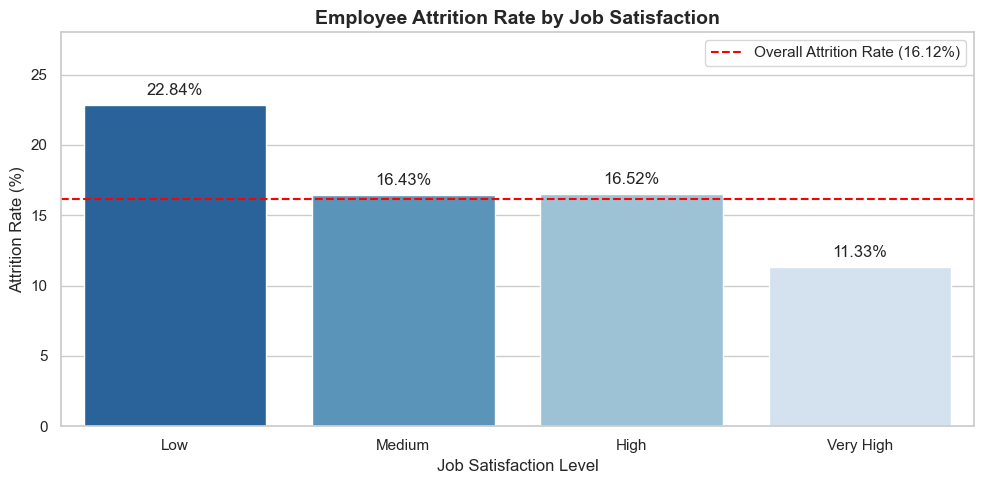

In [18]:
# Give a definition to the order of job satisfaction levels
satisfaction_order = ["Low", "Medium", "High", "Very High"]

# Create a bar chart of attrition rates by job satisfaction
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=satisfaction_attrition,
    x="Satisfaction_Level",
    y="Attrition_Rate",
    order=satisfaction_order,
    hue="Satisfaction_Level",
    hue_order=satisfaction_order,
    palette="Blues_r",
    legend=False
)

# Include the overall attrition rate reference line
plt.axhline(
    y=overall_attrition_rate,
    color="red",
    linestyle="--",
    label=f"Overall Attrition Rate ({overall_attrition_rate:.2f}%)"
)

# Add percentage labels above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

# Format the chart
plt.title(
    "Employee Attrition Rate by Job Satisfaction",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Job Satisfaction Level")
plt.ylabel("Attrition Rate (%)")
plt.ylim(0, 28)
plt.legend()

plt.tight_layout()
plt.show()


### Job Satisfaction: Findings and Business Interpretation

The analysis shows cllear variations in employee turnover rates across the four levels of job satisfaction. 

**Key Findings**

- **Low satisfaction:** Recorded the highest attrition rate at **22.84%** (66 departures out of 289 employees). This sits 6.72 percentage points above the company average of 16.12%.
- **Medium satisfaction:** Recorded a turnover rate of **16.43%** (46 departures out of 280 employees).
- **High satisfaction:** Recorded an attrition rate of **16.52%** (73 departures out of 442 employees).
- **Very high satisfaction:** Recorded the lowest turnover rate at **11.33%**, with 52 departures among 459 employees. This sits 4.79 percentage points below the organisational baseline.
- **Overall Gap:** A difference of **11.51 percentage points** separates the lowest and the highest satisfaction groups.

Although employees reporting very high satisfaction have lower attrition rates than those reporting low satisfaction, the trend is not completely linear across all four categories. Medium and high satisfaction groups show nearly identical departure rates.

**Business Implications**

These findings highlight job satisfaction as a key area for HR teams to explore when addressing staff retention.

Organisations could benefit from gathering and reviewing employee feedback on workplace experiences, leadership support and opportunities for career growth to better understand satisfaction-related concerns.

However, higher satisfaction scores alone do not guarantee lower employee attrition rates. Further evaluation is needed to determine whether targeted retention programmes are effective.

**Analytical Limitations**

Job satisfaction is recorded using a four-point rating scale, which may oversimplify complex employee experiences.

This analysis evaluates satisfaction on its own without adjusting for overlapping factors, such as job role, overtime or tenure.

Furthermore, the dataset is synthetic, and the findings should not be assumed to hold true for real-world organisations without additional evidence.

A chi-square test of independence will be performed later to assess whether job satisfaction and employee attrition are statistically associated.

**Key Takeaway:** Employees with low job satisfaction had the highest rate of attrition at **22.84%**, while those with very high satisfaction had the lowest at **11.33%**.

## 7. Employee Tenure and Attrition Analysis

### Business Question 5: How does employee attrition vary by length of employment?

Employee tenure refers to the amount of time an employee has worked for an organisation.

Understanding attrition patterns across different tenure groups may help HR identify whether employees are more likely to departure during particular stages of their employment.

This analysis uses the `Tenure_Group` feature created during the ETL section, which groups employees into five categories:

- 0–2 years
- 3–5 years
- 6–10 years
- 11–20 years
- 21+ years

**Analytical Approach**

For each tenure group, the analysis will calculate the employee count, number of departures and attrition rate.

Attrition rates will be compared with the overall organisational benchmark of **16.12%** and displayed in a bar chart.

**Business Relevance**

Identifying tenure groups with higher attrition rates may point HR teams to investigate areas such as employee onboarding, early career support or long-term retention practices. 

However, differences in attrition rates do not show that tenure itself causes employees to leave.

The dataset also lacks employment dates and a defined observation period, so it cannot show when departures occurred. 

In [19]:
# Define the correct order of tenure groups
tenure_order = [
    "0-2 years",
    "3-5 years",
    "6-10 years",
    "11-20 years",
    "21+ years"
]

# Calculate attrition statistics for each tenure group
tenure_attrition = (
    df.groupby("Tenure_Group")
    .agg(
        Total_Employees=("EmployeeNumber", "count"),
        Employees_Left=("Attrition_Flag", "sum"),
        Attrition_Rate=("Attrition_Flag", "mean")
    )
    .reindex(tenure_order)
    .reset_index()
)

# Convert attrition rates into percentages
tenure_attrition["Attrition_Rate"] = (
    tenure_attrition["Attrition_Rate"] * 100
).round(2)

# Display results
display(tenure_attrition)


,Tenure_Group,Total_Employees,Employees_Left,Attrition_Rate
0,0-2 years,342,102,29.82
1,3-5 years,434,60,13.82
2,6-10 years,448,55,12.28
3,11-20 years,180,12,6.67
4,21+ years,66,8,12.12


### Employee Tenure Attrition Rate Visualisation

A bar chart is used to compare attrition rates across five employee tenure bands, ranging from 0–2 years to 21+ years.

The groups are ordered by length of service to identify patterns across different stages of employment.

Attrition rates are shown as percentages instead of departure counts, to account for differences in group size between tenure categories.

A dashed reference line marks the overall attrition rate of **16.12%**, for comparison.

This analysis aims to explore whether attrition rates vary with tenure either shorter or longer employment length. However, the results in this analysis are descriptive and cannot establish causation.

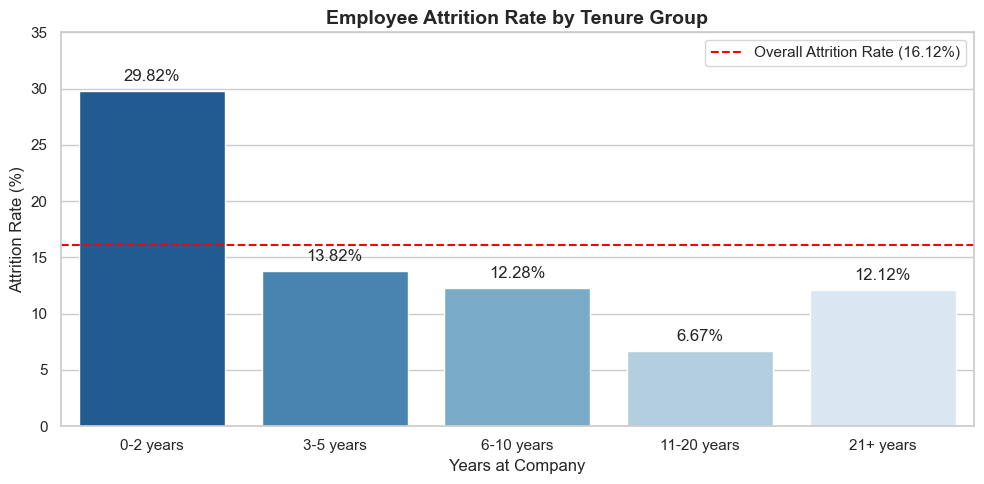

In [20]:
# Create a bar chart of attrition rates by employee tenure
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=tenure_attrition,
    x="Tenure_Group",
    y="Attrition_Rate",
    order=tenure_order,
    hue="Tenure_Group",
    hue_order=tenure_order,
    palette="Blues_r",
    legend=False
)

# Add the overall attrition rate reference line
plt.axhline(
    y=overall_attrition_rate,
    color="red",
    linestyle="--",
    label=f"Overall Attrition Rate ({overall_attrition_rate:.2f}%)"
)

# Add percentage labels above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title(
    "Employee Attrition Rate by Tenure Group",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Years at Company")
plt.ylabel("Attrition Rate (%)")
plt.ylim(0, 35)
plt.legend()

plt.tight_layout()
plt.show()


### Employee Tenure: Findings and Business Interpretation

The analysis identifies differences in employee attrition rates across the five tenure groups.

**Key Findings**

- **0–2 years:** Recorded the highest attrition rate at **29.82%** (102 departures out of 342 employees). This sits 13.70 percentage points above the company baseline of 16.12%.
- **3–5 years:** Recorded a turnover rate of **13.82%** (60 departures out of 434 employees).
- **6–10 years:** Recorded an attrition rate of **12.28%** (55 departures out of 448 employees).
- **11–20 years:** Recorded the lowest turnover rate at **6.67%**, with 12 departures among 180 employees.
- **21+ years:** Recorded an attrition rate of **12.12%**, with 8 departures out of 66 employees.

**General Pattern:** The results show that attrition rates generally decrease across the first four tenure categories before increasing again among employees with over 20 years of service.

Employees with 0–2 years of recorded tenure also accounted for **102 of the 237 departures**, representing approximately 43% of all recorded employee departures.

**Business Implications**

The comparatively high attrition rate among employees in their first two years of service suggests that factors such as onboarding, early-career experiences, professional development and role expectations may warrant closer review by HR to better understand potential retention challenges.

The lower turnover rates among employees with longer service also offer an opportunity to investigate what may contribute to employee engagement and long-term retention.

However, these findings do not prove that shorter tenure itself causes attrition, nor do they guarantee that specific retention programmes will reduce departures.

**Analytical Limitations**

The dataset contains synthetic records and lacks explicit hire dates, departure dates and a defined observation period. Consequently, the results cannot establish when employees departed or measure their probability of departure over time.

The 21+ years category contains only 66 employees, meaning that a small number of additional departures could noticeably affect the group's attrition percentage.

Furthermore, this comparison examines tenure without controlling for other potentially relevant factors, such as job role, overtime status or job satisfaction.

**Key Insight:** Employees in the 0–2 years tenure group recorded the highest attrition rate at **29.82%**, highlighting early employment retention as a priority area for further investigation.

## 8. Statistical Hypothesis Testing

### Introduction

The exploratory analysis showed differences in employee attrition rates across overtime and job satisfaction categories.

Descriptive statistics alone, however cannot tull us whether these relationships are statistically significant.

To examine whether these variables are associated with attrition, two **chi-square tests of independence** will be performed.

A chi-square test tests for a link between two categorical factors by comparing the actual observed data count with the counts that would be seen if the two factors were independent from each other and had no association.

### Hypotheses to Be Tested

**Hypothesis 1 — Overtime and Attrition**

- **Null hypothesis (H₀):** Overtime status and employee attrition are independent; there is no association between them.
- **Alternative hypothesis (H₁):** Overtime status and attrition are associated.

**Hypothesis 2 — Job Satisfaction and Attrition**

- **Null hypothesis (H₀):** Job satisfaction level and employee attrition are independent; there is no association between them.
- **Alternative hypothesis (H₁):** Job satisfaction level and attrition are associated.

### Significance Level

Both tests will use a significance level of **α = 0.05**.

The decision rules are:

- If the p-value is below 0.05, reject the null hypothesis. This provides evidence of a statistically significant association.
- If the p-value is 0.05 or higher, fail to reject the null hypothesis. There is not enough evidence to conclude that an association exists.

Failing to reject the null hypothesis does not prove that the variables are independent.

### Analytical Considerations

Expected cell frequencies will be checked before interpreting the results to assess whether the chi-square approximation is appropriate.

Because the dataset is synthetic, the findings may not reflect real organisations. Furthermore, statistical significance does not demonstrate causation.

The results will be considered alongside the descriptive findings and their business implications.

### Hypothesis Test 1: Overtime and Employee Attrition

The descriptive analysis found that attrition rates among overtime workers was **30.53%** compared to the employees who did not do overtime work at **10.44%**.

This test investigates whether overtime status is statistically associated with employee attrition.

To begin, a contingency table will be created to show a summary of the total of workers in each combination of overtime and turnover categories.

The chi-square test will then be applied using the observed counts.

In [21]:
# Create a contingency table for overtime and attrition
overtime_contingency = pd.crosstab(
    df["OverTime"],
    df["Attrition"]
)

# Arrange and keep the category order consistent 
overtime_contingency = overtime_contingency.reindex(
    index=["No", "Yes"],
    columns=["No", "Yes"]
)

print("Overtime vs Attrition Contingency Table:")
display(overtime_contingency)


Overtime vs Attrition Contingency Table:


Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


In [22]:
# Perform chi-square test of independence
chi2, p_value, dof, expected = chi2_contingency(overtime_contingency)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Degrees of freedom: {dof}")
print(f"Minimum expected frequency: {expected.min():.2f}")

# Interpret the result at the 5% significance level
alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
    print("There is a statistically significant association between overtime and attrition.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of an association between overtime and attrition.")


Chi-square statistic: 87.5643
P-value: 0.000000
Degrees of freedom: 1
Minimum expected frequency: 67.07
Decision: Reject the null hypothesis.
There is a statistically significant association between overtime and attrition.


#### Overtime Hypothesis Test: Findings and Business Interpretation

**Statistical Results**

The chi-square test returned a statistic of **87.5643**, with **1 degree of freedom** and a **p-value below 0.000001**.

As the p-value is below the significance level of 0.05, the null hypothesis is rejected. This provides strong statistical evidence of an association between overtime working and employee turnover.

The minimum expected cell frequency was **67.07**, which is above the commonly used threshold of 5. This supports the suitability of the chi-square approximation.

**Business Interpretation**

The earlier descriptive analysis showed that staff working overtime had an attrition rate of **30.53%**, compared to just **10.44%** for those employees who did not.

The chi-square test provides strong evidence against the null hypothesis of independence, indicating that the association between overtime and attrition is statistically significant.

For HR, these findings highlight overtime and workload management as areas worth investigating when reviewing employee retention.

However, this test does not prove that overtime alone causes staff to leave. Other overlapping factors, such as job role, workplace environment or job satisfaction, may also play a key role.

**Analytical Limitations**

The dataset is synthetic, so these findings should not automatically be generalised to real organisations.

Furthermore, while the chi-square test provides strong evidence of a statistical association, it does not establish a direct cause-and-effect relationship or account for other workplace factors that may influence employee attrition.

**Key Insight:** Overtime status shows a statistically significant association with employee attrition (p < 0.000001). Employees who work overtime also had a substantially higher departure rate, making workload management a priority area for further HR review.